# VALORA AI: Apartment Asking Price Estimation and Prediction Uncertainty in Montenegro
## Notebook 01: Exploratory Data Analysis

**Project:** VALORA AI, real estate valuation and market analysis for Montenegro
**Question:** Can machine learning estimate **apartment asking prices** in Montenegro from location, size and other available characteristics?
**This notebook:** checks where every record comes from, cleans the real apartment listings with one fixed set of rules, explores prices, sizes and cities, and exports the single dataset that `02_modelling.ipynb` uses.

## 1. TL;DR

- The raw file has **6,913 rows, but only 1,986 are real online listings**. The rest are simulated, generated or professional appraisals. **The 2,000 simulated rows are labelled `data_source = "Online listing"` and `is_synthetic = False`**, so real listings are identified by checking several provenance columns together.
- After one documented cleaning procedure, **1,376 real apartment listings** form the primary population, plus **4 valid luxury listings** kept for a sensitivity check. Removed: 513 houses or unclear types, 7 misclassified types, **36 rentals** (all under €10,000), 2 price errors, 1 impossible area and **47 exact re-posts**.
- Location was the biggest data problem. The platform `city` field leaves **668 of 1,376 (49%)** apartments without a city. Reading the structured location text brings this to **289 (21%)**, and 15 settlement names checked against the official Monstat register bring it to **33 (2.4%)**.
- Size explains a lot of the price, and location changes the price per m²: on the coast (Tivat, Kotor, Budva) the median asking price per m² is clearly higher than in Podgorica, Nikšić or Cetinje. The sample is **not representative** of the whole market: one platform (Estitor) only covers Podgorica, with about 20 listings per neighbourhood.

## 2. Introduction & motivation

Valuing a property in Montenegro usually means a manual search for comparable listings. **VALORA AI** is a data science research project that examines how accurately apartment asking prices in Montenegro can be estimated from available property characteristics, and how reliably the uncertainty of these estimates can be quantified.

This notebook prepares and explores the data for that question: **how well can the advertised asking price (`price_eur`) of an apartment be estimated from its size, number of rooms and city?**

Three points matter for everything that follows:

1. The target is the **asking price**, the price written in an online advert. Asking prices are **not** sale prices and **not** certified market values.
2. Only **real** listings can teach a model about the real market. Simulated and generated rows were useful for early experiments, but they must not be mixed in.
3. A model is only as good as its inputs. In this dataset, location turned out to be the input that needed the most care.

Time trends and an ARIMA forecast are **not** part of this work: the listings have no publication or collection dates (Section 7.9).

## 3. Data provenance

| File | What it is | Used how |
|---|---|---|
| `data/raw/VALORA_AI_FINAL_COLAB.csv` | My combined dataset: 6,913 rows, 59 columns | **Only input** of this notebook |
| `data/raw/valora_cleaned_step2.csv` | An earlier partly cleaned version: 4,036 rows, 48 columns | Only for comparison in the Appendix, never as a model input |
| `data/reference/settlement_mapping.csv` | Settlement → municipality table, with evidence from the official Monstat 2023 settlement register | Location cleaning (Section 7.6) |

**Sources inside the raw file**

- **Real online listings:** I collected these from the public property portals **Realitica** (including its "Adriatic" section) and **Estitor**.
- **Simulated** and **synthetic (generated)** rows were created artificially for earlier experiments.
- **Professional appraisal** rows come from valuation reports. Their labels "reviewed" and "unverified" are the dataset's own labels, not an independent quality check.

**What is not known (documented, not invented):**
- the exact date or period when the listings were collected;
- the platforms' terms of use for scraped data;
- whether the raw file may be redistributed.

The raw file also contains file paths of appraisal reports that may include personal names. The notebooks therefore never print appraisal text columns, and the exported dataset contains no URLs, platform IDs, titles or descriptions. See `docs/privacy_and_data_rights.md`.

**Template:** this notebook follows the 13 sections of the instructor's `dsb_cap_template-main/notebooks/01_eda.ipynb`. The template ZIP was not available; the unzipped template folder was used and its checksums were recorded.

## 4. Data dictionary

**Raw columns used** (original names, many in Montenegrin):

| Column | Meaning | Units / values |
|---|---|---|
| `listing_id` | ID of the advert on its platform | text; stays local, not exported |
| `izvor` | Platform ("source") | Realitica, Realitica Adriatic, Estitor, SIMULATED |
| `property_type` | Property type as scraped | many spellings of *stan* (apartment), *kuća* (house), … |
| `price_eur` | **Asking price (target)** | EUR |
| `area_m2` | Living area | m² |
| `sobe` | Number of rooms in the advert (*jednosoban* = one-bedroom) | count |
| `kupatila` | Bathrooms | count (mostly missing) |
| `lokacija` | Location text, e.g. "Zabjelo, Podgorica," | text |
| `city` | Platform city field (often broken for Realitica) | text |
| `naslov`, `opis`, `url` | Title, description, link | text; used only for checks, never exported |
| `provjera` | My own manual check flag | "OK", "PROVJERITI", … |
| `data_origin`, `data_source`, `is_synthetic` | Provenance labels | see Section 6 |
| `cijena_po_m2`, `price_per_m2_calculated` | Price per m² = price ÷ area | EUR/m²; **computed from the target**, so EDA only |

**Columns created here and exported** (`data/processed/valora_apartments_clean.csv`):

| Column | Meaning | Units / values |
|---|---|---|
| `record_id` | Internal ID (VAL-0001 …), stable while the raw file is unchanged | text |
| `platform` | Realitica / Realitica Adriatic / Estitor (audit only, **not** a model feature) | category |
| `population` | `primary` (main analysis) or `extended only` (4 valid luxury listings) | category |
| `price_eur` | Asking price (target) | EUR |
| `area_m2` | Living area | m² |
| `rooms`, `is_studio` | Rooms; studios (*garsonjera*) = 0 | count, True/False |
| `price_per_m2` | price ÷ area (EDA only, **never** a model input) | EUR/m² |
| `city_original` | Platform `city` field if it is a real municipality | 25 municipalities or Unknown |
| `city_explicit`, `city_explicit_method` | City from explicit location text only | municipality / Unknown |
| `city_clean`, `city_method` | Explicit location + reviewed settlement mapping (main version) | municipality / Unknown |
| `neighbourhood` | First token of the location text | text |
| `repeat_group`, `repeat_group_size`, `repeat_cross_platform`, `repeat_rooms_conflict` | Group of listings that are probably the same flat | ID, count, flags |
| `source_check_flag` | The `provjera` flag simplified to OK / check | category |

## 5. Setup

**What this code does:** Imports the libraries, finds the project folder, and loads the project's own cleaning rules from `src/valora_prep.py` and the chart style from `src/valora_plot.py`.

**Why we need it:** Keeping the rules in one Python file means the notebook, the tests and anyone re-running the project use exactly the same rules. Paths are built from the project root, so the notebook runs on any computer.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / 'data' / 'raw').is_dir() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import valora_prep as vp
import valora_plot as vplot

vplot.apply_style()
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
RAW_PATH = ROOT / 'data' / 'raw' / vp.RAW_FILE
FIG = ROOT / 'docs' / 'figures'
RES = ROOT / 'docs' / 'results'
PROCESSED = ROOT / 'data' / 'processed'
for folder in (FIG, RES, PROCESSED, ROOT / 'data' / 'private'):
    folder.mkdir(parents=True, exist_ok=True)
print('Project folder found:', ROOT.name)
print('Python:', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__)

Project folder found: valora_ai
Python: 3.11.9 | pandas 3.1.1 | numpy 2.4.6


**What this code does:** Checks the raw file's fingerprint (SHA-256 checksum) and then loads it.

**Why we need it:** The checksum shows the original data is exactly the file that was audited and has not been edited. If it changes, the notebook stops instead of silently giving different results.

In [2]:
checksum = vp.file_sha256(RAW_PATH)
assert checksum == vp.RAW_SHA256, 'The raw file has changed! Restore the original before running.'
raw = vp.load_raw(RAW_PATH)
print(f'Raw file OK (sha256 {checksum[:12]}...) - {raw.shape[0]:,} rows x {raw.shape[1]} columns')

Raw file OK (sha256 d3ddafe175a7...) - 6,913 rows x 59 columns


## 6. First look

**What this code does:** Shows the size of the raw table, the data type of the main columns, and how many values are filled in.

**Why we need it:** Before cleaning anything, it is necessary to know what is in the file. Nine columns turn out to be completely empty (leftovers from merging files).

In [3]:
overview = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'non_missing': raw.notna().sum(),
                         'unique': raw.nunique()})
print('Completely empty columns:', overview.index[overview['non_missing'].eq(0)].tolist())
display(overview.loc[['listing_id', 'izvor', 'property_type', 'price_eur', 'area_m2', 'sobe', 'kupatila',
                      'lokacija', 'city', 'data_origin', 'data_source', 'is_synthetic']])

Completely empty columns: ['verified_area_m2', 'Listing_ID', 'Property_Type', 'Land_Area_m2', 'Bedrooms', 'Floor', 'Condition', 'Year_Built', 'Price_per_m2_EUR', 'Data_Source']


,dtype,non_missing,unique
listing_id,str,5986,5986
izvor,str,3986,4
property_type,str,6911,18
price_eur,float64,6401,2932
area_m2,float64,6129,1463
sobe,float64,3454,12
kupatila,float64,386,5
lokacija,str,3986,286
city,str,6825,203
data_origin,str,3986,2


**What this code does:** Shows three example rows of real listings (only the columns needed for analysis; no titles, descriptions or links).

**Why we need it:** To see what one record looks like. Free text and URLs are never printed, because they can contain agents' names or other personal details.

In [4]:
display(raw.loc[raw['data_origin'].eq('REAL'), ['izvor', 'property_type', 'price_eur', 'area_m2', 'sobe', 'lokacija', 'city']]
        .groupby('izvor').head(1))

,izvor,property_type,price_eur,area_m2,sobe,lokacija,city
0,Realitica,kuća,650000.0,250.0,NaN,"Bar, Bar,",NaN
1437,Estitor,Stan,139000.0,43.0,1.0,Stari Aerodrom,Podgorica
1852,Realitica Adriatic,stan,440000.0,77.0,2.0,"Bečići, Budva Okolina, Crna Gora",Budva Okolina


### 6.1 Where does each row come from?

**What this code does:** Classifies every row as a real listing, simulated, synthetic or appraisal (`vp.assign_provenance`), then compares this with the original label columns.

**Why we need it:** This is the most important check in the project. If artificial rows were treated as real adverts, every result would be wrong.

In [5]:
raw['provenance'] = vp.assign_provenance(raw)
prov_check = vp.provenance_label_check(raw, raw['provenance'])
display(prov_check)
prov_check.to_csv(RES / 'provenance_label_check.csv', index=False)
assert (raw['provenance'] == 'UNCLASSIFIED').sum() == 0

,provenance,data_source,data_origin,is_synthetic,has_url,rows
0,Appraisal (reviewed label),Professional appraisal - reviewed,(empty),False,False,50
1,Appraisal (unverified label),Professional appraisal - unverified,(empty),False,False,877
2,Real online listing,Online listing,REAL,False,True,1986
3,Simulated,Online listing,SIMULATED,False,False,2000
4,Synthetic (generated),Synthetic - generated,(empty),True,False,2000


**What the table shows:** the **2,000 simulated rows have `data_source = "Online listing"` and `is_synthetic = False`**, exactly like real listings. Only `data_origin = SIMULATED` (and `izvor = SIMULATED`, no URL) gives them away. A filter on `data_source` or `is_synthetic` alone would have mixed 2,000 artificial rows into the "real" market data. The rule used here requires all provenance signals to agree, and an automatic test (`tests/test_data.py`) checks it.

**What this code does:** Draws a bar chart of the number of rows per provenance group.

**Why we need it:** To show at a glance that less than a third of the file is real market data.

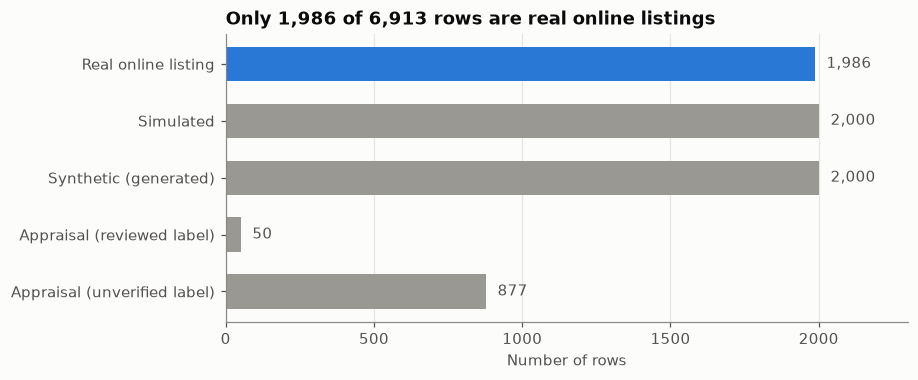

In [6]:
counts = raw['provenance'].value_counts().reindex(vp.PROVENANCE_ORDER)
fig, ax = plt.subplots(figsize=(8, 3.4))
colors = [vplot.BLUE if p == vp.PROVENANCE_REAL else vplot.GRAY for p in counts.index]
ax.barh(counts.index[::-1], counts.values[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(counts.values[::-1]):
    ax.text(v + 40, y, f'{v:,}', va='center', color=vplot.INK_2)
ax.set_xlabel('Number of rows')
ax.set_title('Only 1,986 of 6,913 rows are real online listings')
ax.grid(axis='y', visible=False)
ax.set_xlim(0, counts.max() * 1.15)
vplot.save(fig, FIG, 'eda_01_provenance'); plt.show()

Blue = real advertised listings, the only rows used for the market analysis and the model. Grey = rows that are not market listings: they stay in the raw file but are excluded.

## 7. Data quality audit

All rules are applied by one function, `vp.clean_real_listings`, in a fixed order. Every row gets **at most one** exclusion reason (the first rule it breaks), so the counts add up exactly. The raw file is never changed. Each problem is examined first, then the whole procedure is run (7.8).

### 7.1 Property types

**What this code does:** Groups the 18 different spellings of property type into apartment / house-villa / unclear, for real listings only.

**Why we need it:** The question is about apartments. Houses and villas are a different market and would distort apartment prices.

In [7]:
real_raw = raw[raw['provenance'] == vp.PROVENANCE_REAL].copy()
real_raw['property_group'] = vp.property_type_group(real_raw['property_type'])
display(pd.crosstab(real_raw['property_type'].fillna('(missing)'), real_raw['property_group']))

property_group,Apartment,House / villa,Unclear / other
property_type,,,
(missing),0,0,2
Kuca,0,2,0
Kuća,0,28,0
Kuća/Vila,0,8,0
Nepoznato,0,0,6
Stan,506,0,0
kuca,0,2,0
kuća,0,408,0
kuća (provjeriti),0,0,12


**What this code does:** Finds real listings typed as apartment (`stan`) whose title starts with *kuću* (house) or *poslovni prostor* (commercial space).

**Why we need it:** The type label and the title contradict each other, so it is not certain that these are apartments.

In [8]:
apts = real_raw[real_raw['property_group'] == 'Apartment'].copy()
word = vp.title_type_word(apts['naslov'])
print('First word of the title for apartments:', word.value_counts().to_dict())
print('Type conflicts (title says house):', int(word.isin(['kuću', 'poslovni']).sum()))

First word of the title for apartments: {'stan': 1021, 'prodaja,': 415, 'riviera': 19, 'kuću': 7, 'sergej': 6, 'goran': 2, 'luxestate': 2, 'trajkovic': 1}
Type conflicts (title says house): 7


**Result:** 1,473 real rows are typed as apartments. In 7 of them the title describes a house, so they are removed as *misclassified*. (The words *prodaja*, *riviera*, … are other platforms' title formats, which is fine.)

### 7.2 Rentals mixed with sale prices

**What this code does:** Plots the asking price of all real apartments on a logarithmic scale and lists the smallest prices.

**Why we need it:** A log scale shows very small and very large prices on one chart. A few typos were expected; the chart instead shows a separate cluster of adverts that are rents, not sales.

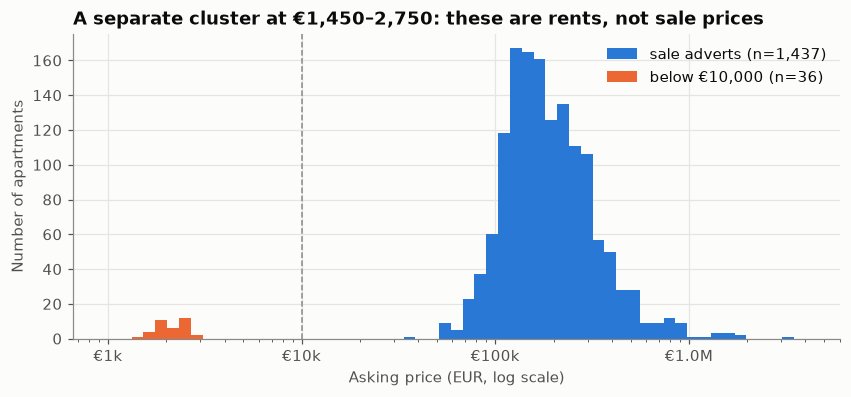

{'count': 36.0, 'mean': 2136.0, 'std': 319.0, 'min': 1450.0, '25%': 1950.0, '50%': 2200.0, '75%': 2350.0, 'max': 2750.0}
Their area (m2): {'count': 36.0, 'mean': 49.0, 'std': 10.0, 'min': 25.0, '25%': 43.0, '50%': 47.0, '75%': 53.0, 'max': 78.0}
Manual check flag (provjera) on these rows: {'PROVJERITI: cijena': 19, 'PROVJERITI': 13, 'sumnjivo niska cijena': 4}


In [9]:
fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.logspace(np.log10(1_000), np.log10(4_000_000), 60)
low = apts['price_eur'] < vp.PRICE_MIN_SALE
ax.hist(apts.loc[~low, 'price_eur'], bins=bins, color=vplot.BLUE, label=f'sale adverts (n={(~low).sum():,})')
ax.hist(apts.loc[low, 'price_eur'], bins=bins, color=vplot.ORANGE, label=f'below €10,000 (n={low.sum()})')
ax.set_xscale('log'); ax.xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.axvline(vp.PRICE_MIN_SALE, color=vplot.INK_3, lw=1, ls='--')
ax.set_xlabel('Asking price (EUR, log scale)'); ax.set_ylabel('Number of apartments')
ax.set_title('A separate cluster at €1,450–2,750: these are rents, not sale prices')
ax.legend(loc='upper right')
vplot.save(fig, FIG, 'eda_02_rent_vs_sale'); plt.show()
print(apts.loc[low, 'price_eur'].describe().round(0).to_dict())
print('Their area (m2):', apts.loc[low, 'area_m2'].describe().round(0).to_dict())
print("Manual check flag (provjera) on these rows:", apts.loc[low, 'provjera'].value_counts().to_dict())

**What it means:** all 36 "apartments" under €10,000 cost between €1,450 and €2,750 for 25–78 m², which would be €25–90 per m². That is not a plausible sale price anywhere in Montenegro, and it matches monthly or seasonal rents. I had already flagged them in my manual check column ("PROVJERITI: cijena", "sumnjivo niska cijena"). The gap between the two clusters is wide (nothing between €2,750 and €37,000), so the €10,000 limit is not a fine-tuned threshold. They are removed as **rentals**, because they answer a different question (rent, not sale).

### 7.3 Price errors and impossible values

**What this code does:** Compares `price_eur` with the price written in the advert title (Realitica titles contain it), and lists apartments with an area below 15 m².

**Why we need it:** If two copies of the same information disagree strongly, at least one is wrong. A 1 m² apartment is physically impossible.

In [10]:
apts['title_price'] = vp.title_price(apts['naslov'])
gap = (apts['title_price'] - apts['price_eur']).abs() / apts['price_eur']
display(apts.loc[apts['title_price'].notna() & (gap > 0), ['izvor', 'price_eur', 'title_price', 'area_m2']]
        .assign(difference_pct=(gap * 100).round(1)))
display(apts.loc[apts['area_m2'] < vp.AREA_MIN_VALID, ['izvor', 'price_eur', 'area_m2', 'provjera']])

,izvor,price_eur,title_price,area_m2,difference_pct
589,Realitica,2450.0,166900,62.0,6712.2
670,Realitica,144900.0,144990,43.0,0.1
1377,Realitica,1700.0,1800,55.0,5.9
1391,Realitica,79960.0,160225,64.0,100.4
1392,Realitica,79960.0,114322,43.0,43.0


,izvor,price_eur,area_m2,provjera
650,Realitica,135150.0,1.0,provjeriti kvadraturu


**What it means:** five rows have a title price different from `price_eur`.
- Two of them (rows with €2,450 and €1,700) are already removed as rentals.
- One differs by only 0.06% (€144,900 vs €144,990, a typo) and is kept.
- **Two are removed as data errors.** Their `price_eur` is €79,960, but the titles say €160,225 and €114,322. It is not possible to tell which value is correct, so no value is guessed.
- The 1 m² apartment is removed as an **invalid physical value**; its source flag already says "provjeriti kvadraturu" (check area).

### 7.4 Rooms: studios versus missing values

**What this code does:** Counts the room numbers and links the Estitor title words (*garsonjera*, *jednosoban*, …) to the `sobe` column.

**Why we need it:** A studio (*garsonjera*) has no separate bedroom. In the raw file studios have `sobe` empty, which a model would wrongly treat as 'unknown'.

In [11]:
est = apts[apts['izvor'] == 'Estitor']
word = est['naslov'].str.extract(r'Prodaja, (\w+)')[0]
display(pd.crosstab(word, est['sobe'].fillna(-1).astype(int).replace(-1, 'missing')))
rooms = vp.rooms_from_listing(apts)
print('Rooms after fixing studios:', rooms.value_counts(dropna=False).sort_index().to_dict())

sobe,1,2,3,4,missing
0,,,,,
dvosoban,0,150,0,0,0
garsonjera,0,0,0,0,22
jednosoban,170,0,0,0,0
stan,0,0,0,0,3
trosoban,0,0,65,0,0
četvorosoban,0,0,0,5,0


Rooms after fixing studios: {0.0: 22, 1.0: 574, 2.0: 463, 3.0: 165, 4.0: 11, 5.0: 1, 6.0: 1, nan: 236}


**What it means:** all 22 *garsonjera* adverts have empty `sobe`, so they are studios, not missing values. They are set to **0 rooms**, with an `is_studio` flag. The remaining missing values come from Realitica titles that give no room count ("stan 48 m2"). These are truly unknown and will be filled inside the model pipeline using training data only.

`sobe` counts rooms as written in the advert (*jednosoban* = one-bedroom), so the column is called `rooms`, without claiming it is an exact bedroom count.

### 7.5 Missing values

**What this code does:** Computes the share of missing values per column for real apartment listings and draws it as a bar chart.

**Why we need it:** Columns with many gaps cannot be reliable model inputs. Bathrooms (`kupatila`) are a good example.

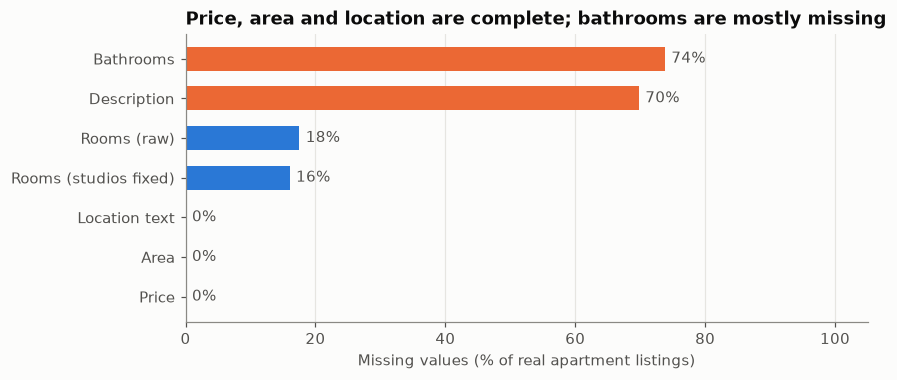

Bathrooms present by platform: {'Estitor': 386, 'Realitica': 0, 'Realitica Adriatic': 0}


In [12]:
cols = {'price_eur': 'Price', 'area_m2': 'Area', 'sobe': 'Rooms (raw)', 'kupatila': 'Bathrooms',
        'lokacija': 'Location text', 'opis': 'Description'}
miss = (apts[list(cols)].isna().mean() * 100).rename(index=cols).sort_values()
miss.loc['Rooms (studios fixed)'] = rooms.isna().mean() * 100
miss = miss.sort_values()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(miss.index, miss.values, color=[vplot.ORANGE if v > 50 else vplot.BLUE for v in miss.values], height=0.6)
for y, v in enumerate(miss.values):
    ax.text(v + 1, y, f'{v:.0f}%', va='center', color=vplot.INK_2)
ax.set_xlim(0, 105); ax.set_xlabel('Missing values (% of real apartment listings)')
ax.set_title('Price, area and location are complete; bathrooms are mostly missing')
ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'eda_03_missing_values'); plt.show()
print('Bathrooms present by platform:', apts.groupby('izvor')['kupatila'].apply(lambda s: s.notna().sum()).to_dict())

**What it means:** price, area and location text are always present. Bathrooms exist for only about a quarter of the apartments, and **only on Estitor** (never on Realitica or Realitica Adriatic). If bathrooms were used, the model would really be learning "which website the advert came from", so bathrooms are **not** used as a feature. Descriptions are not used either: some contain prices (that would leak the answer) and some contain agents' names.

### 7.6 Location: the biggest data problem

**What this code does:** Shows what the platform `city` field contains for Realitica apartments.

**Why we need it:** The earlier modelling used a city column with 703 'Unknown' values. The reason for so many missing cities had to be found.

In [13]:
print(apts[apts['izvor'] == 'Realitica']['city'].value_counts().head(8).to_dict())
print(apts[apts['izvor'] == 'Realitica']['lokacija'].value_counts().head(8).to_dict())

{'stan 1 sobe': 205, 'stan 2 sobe': 177, 'Podgorica': 80, 'stan 3 sobe': 58, 'Ulcinj': 56, 'Kolašin': 56, 'Tivat': 42, 'Bar': 32}
{'Budva,': 128, 'Đenovići,': 45, 'Kolašin, Kolašin,': 44, 'Tivat, Tivat,': 42, 'Ulcinj, Ulcinj,': 40, 'Igalo,': 35, 'Bečići,': 33, 'Zabjelo, Podgorica,': 31}


**What it means:** for Realitica the `city` field often contains pieces of the title ("stan 1 sobe" = "apartment 1 room") or a neighbourhood. The **location text `lokacija` has a clear structure** instead: "Neighbourhood, Municipality," or just "Settlement,".

It is read with simple, checkable rules (`vp.resolve_city`):

| Method | Rule |
|---|---|
| **Original valid city** | The platform city field is one of Montenegro's 25 municipalities and agrees with the location (for Estitor, also with the city in the link). |
| **Explicit location match** | A municipality name is a **whole** comma-separated part of `lokacija` ("Centar, **Nikšić**,"). Parts of words are never matched, so "Bar" can never match inside "Barutana". |
| **Reviewed settlement mapping** | `lokacija` is one of 15 settlement names (e.g. *Igalo*, *Bečići*) that the official **Monstat 2023 settlement register** assigns to exactly one municipality. |
| **Ambiguous** | Names that can mean more than one place: *Centar*, *Luštica*, *Prijevor* (two municipalities), *Zelenika* (Herceg Novi settlement, but also a Podgorica neighbourhood in these adverts). These stay Unknown. |
| **Conflict** | Two sources disagree (e.g. Estitor lists *Zeta* under Podgorica, but Zeta has been its own municipality since 2022). These stay Unknown. |

A city is never guessed from the price, and "near X" phrases from descriptions are never used.

**What this code does:** Shows the settlement mapping table with the number of listings each mapping affects.

**Why we need it:** Every mapping must be checkable, so each one is documented with its evidence and review status.

In [14]:
settlements, not_applied = vp.load_settlement_mapping(ROOT / 'data' / 'reference' / 'settlement_mapping.csv')
mapping = pd.read_csv(ROOT / 'data' / 'reference' / 'settlement_mapping.csv')
single = apts['lokacija'].map(vp.location_tokens)
token_counts = single.explode().map(vp.norm).value_counts()
mapping['records_in_real_apartments'] = mapping['settlement'].map(vp.norm).map(token_counts).fillna(0).astype(int)
display(mapping[['settlement', 'assigned_municipality', 'applied', 'records_in_real_apartments', 'ambiguity_status', 'review_status']])
print('Applied mappings:', len(settlements))

,settlement,assigned_municipality,applied,records_in_real_apartments,ambiguity_status,review_status
0,Đenovići,Herceg Novi,yes,45,unique name in register,pending author review
1,Igalo,Herceg Novi,yes,35,unique name in register,pending author review
2,Kumbor,Herceg Novi,yes,31,unique name in register,pending author review
3,Topla,Herceg Novi,yes,28,unique name in register,pending author review
4,Bijela,Herceg Novi,yes,27,unique exact name in register,pending author review
5,Savina,Herceg Novi,yes,15,unique name in register,pending author review
6,Baošići,Herceg Novi,yes,11,unique name in register,pending author review
7,Meljine,Herceg Novi,yes,10,unique name in register,pending author review
8,Njivice,Herceg Novi,yes,7,unique name in register,pending author review
9,Kamenari,Herceg Novi,yes,6,unique name in register,pending author review


Applied mappings: 15


(These counts are for all real apartment listings before the remaining cleaning steps. The final counts per method are in 7.8.)

### 7.7 Duplicates and repeated listings

**What this code does:** Looks for (a) repeated IDs or links, (b) exact re-posts (same platform, identical content, different ID), and (c) listings that are probably the same flat (same city, neighbourhood, price and area).

**Why we need it:** The same flat advertised twice would count twice. Worse, one copy could end up in the training set and the other in the test set, so the model would be tested on a flat it has already seen (data leakage).

In [15]:
print('Repeated listing IDs:', int(apts['listing_id'].duplicated().sum()), '| repeated URLs:', int(apts['url'].duplicated().sum()))
same_content = apts.duplicated(subset=vp.EXACT_DUPLICATE_COLUMNS, keep=False)
print('Apartments in exact-content groups (before other cleaning):', int(same_content.sum()))

Repeated listing IDs: 0 | repeated URLs: 0
Apartments in exact-content groups (before other cleaning): 95


**Rule for exact re-posts (approved decision D3):** if two adverts on the same platform have identical platform, price, area, rooms, location text, title, description and bathrooms, only the advert with the **smallest platform ID** (the oldest posting) is kept. The others are removed and counted. The rule runs **after** the validity rules, so a rental re-post is counted once, as a rental.

**Probable same flat (not deleted):** listings with the same cleaned city, neighbourhood, price and area get the same `repeat_group`. They might be the same flat on two platforms, or two identical flats in one new building, so **all of them are kept**. The modelling notebook only makes sure that a whole group always stays on one side of a train/test split. These groups are checked for possible wrong links in 7.8.

### 7.8 The complete cleaning procedure

**What this code does:** Runs every rule in order with `vp.clean_real_listings` and shows the cleaning flow table: rows before, rows after, rows affected and the reason.

**Why we need it:** This gives one reproducible path from 6,913 raw rows to the final analysis population, with every removed row accounted for.

In [16]:
real, flow = vp.clean_real_listings(raw.drop(columns=['provenance']), settlements, not_applied)
display(flow)
flow.to_csv(PROCESSED / 'cleaning_flow.csv', index=False)
print(real['population'].value_counts().to_dict())

,step,rows_before,rows_after,rows_affected,kind,reason
0,Exclude simulated,6913,4913,2000,provenance,Not a real advertised listing
1,Exclude synthetic (generated),4913,2913,2000,provenance,Not a real advertised listing
2,Exclude appraisal (reviewed label),2913,2863,50,provenance,Not a real advertised listing
3,Exclude appraisal (unverified label),2863,1986,877,provenance,Not a real advertised listing
4,Not an apartment (house / villa),1986,1536,450,cleaning,Different property type
5,Not an apartment (unclear / commercial),1536,1473,63,cleaning,Different property type
6,Misclassified type (title says house / commerc...,1473,1466,7,cleaning,Misclassified property type
7,"Rental listing (price < EUR 10,000)",1466,1430,36,cleaning,"Rental, not a sale"
8,Data error: price conflicts with title (> 5%),1430,1428,2,cleaning,Data error
9,Invalid physical value (area < 15 m2),1428,1427,1,cleaning,Invalid physical value


{'primary': 1376, 'excluded': 606, 'extended only': 4}


**What this code does:** Draws the cleaning flow as a chart: how many rows remain after each step.

**Why we need it:** A picture of the funnel is easier to explain than the table.

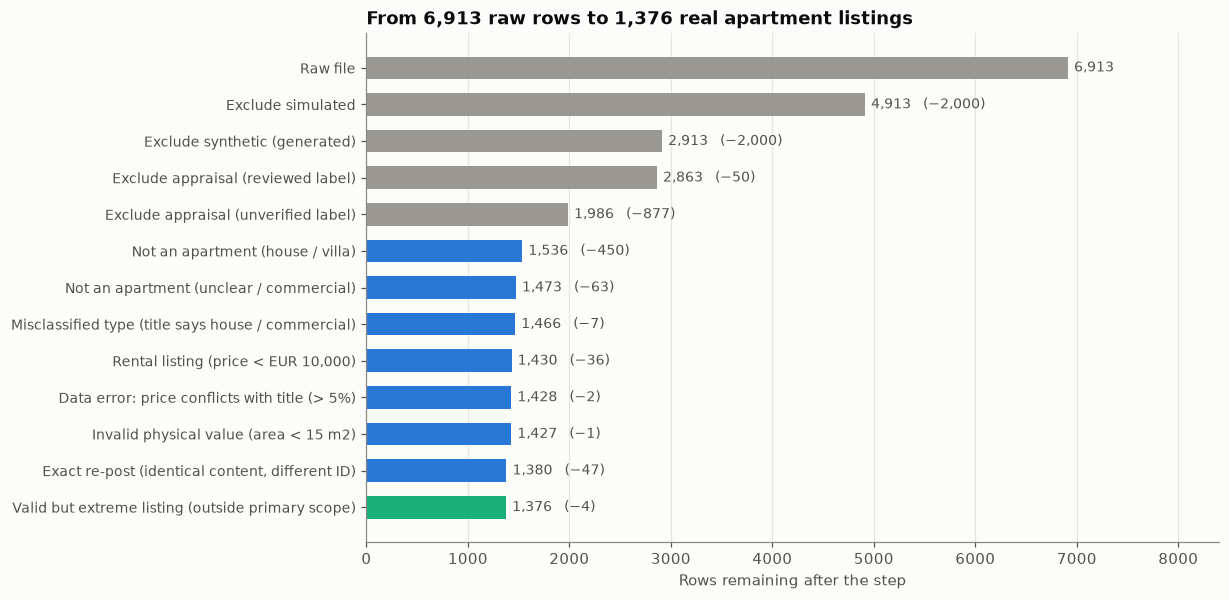

In [17]:
labels = ['Raw file'] + flow['step'].tolist()
remaining = [flow['rows_before'].iloc[0]] + flow['rows_after'].tolist()
fig, ax = plt.subplots(figsize=(10, 6))
ypos = np.arange(len(labels))[::-1]
kinds = ['start'] + flow['kind'].tolist()
color = {'start': vplot.GRAY, 'provenance': vplot.GRAY, 'cleaning': vplot.BLUE, 'scope': vplot.AQUA}
ax.barh(ypos, remaining, color=[color[k] for k in kinds], height=0.62)
for y, r, a in zip(ypos, remaining, [None] + flow['rows_affected'].tolist()):
    txt = f'{r:,}' + (f'   (−{a:,})' if a else '')
    ax.text(r + 60, y, txt, va='center', color=vplot.INK_2, fontsize=9)
ax.set_yticks(ypos, labels, fontsize=9)
ax.set_xlim(0, 8400); ax.set_xlabel('Rows remaining after the step')
ax.set_title('From 6,913 raw rows to 1,376 real apartment listings')
ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'eda_04_cleaning_flow'); plt.show()

Grey = non-market rows (provenance). Blue = data quality rules. Green = the **scope** step: 4 valid luxury listings that are outside the primary population but stay in the exported file for a sensitivity analysis.

**What this code does:** Summarises the excluded real listings by the **type** of problem: data error, rental, misclassified type, invalid value, duplicate, or a valid but extreme listing.

**Why we need it:** These are very different problems. A valid luxury flat is **not** an error just because it is expensive, so it must not be described as one.

In [18]:
reason_type = real['exclusion_reason'].map(vp.EXCLUSION_CATEGORIES)
reason_type = reason_type.where(real['population'] != 'extended only', 'Valid but extreme (kept, sensitivity only)')
summary = (reason_type[real['population'] != 'primary'].value_counts()
           .rename_axis('category').rename('real listings').reset_index())
display(summary)
summary.to_csv(PROCESSED / 'exclusion_summary.csv', index=False)
real.loc[real['population'] != 'primary', ['record_id', 'platform', 'exclusion_reason', 'population', 'price_eur', 'area_m2']] \
    .assign(exclusion_reason=lambda d: d['exclusion_reason'].replace('', 'Valid but extreme listing (outside primary scope)')) \
    .to_csv(PROCESSED / 'exclusion_log.csv', index=False)
display(real.loc[real['population'] == 'extended only', ['platform', 'price_eur', 'area_m2', 'rooms', 'price_per_m2', 'city_clean']].round(0))

,category,real listings
0,Different property type,513
1,Duplicate,47
2,"Rental, not a sale",36
3,Misclassified property type,7
4,"Valid but extreme (kept, sensitivity only)",4
5,Data error,2
6,Invalid physical value,1


,platform,price_eur,area_m2,rooms,price_per_m2,city_clean
1523,Estitor,1500000.0,450.0,4.0,3333.0,Podgorica
196,Realitica,950000.0,400.0,3.0,2375.0,Budva
205,Realitica,3300000.0,347.0,3.0,9510.0,Budva
1305,Realitica,850000.0,353.0,3.0,2408.0,Unknown


**The four valid luxury listings** (above) are outside the earlier research ranges (price ≤ €2M, area ≤ 350 m², €300–15,000 per m²). Nothing suggests they are errors: three are 353–450 m² flats with ordinary prices per m² (about €2,400–3,300), and the fourth is a 347 m² Budva flat advertised at €3.3M (≈ €9,500 per m²). They form a very small and different segment. They are kept in the exported file (`population = extended only`), and the modelling notebook reports how a model trained with and without them behaves. **The objective validity rules, not these ranges, removed the rentals and errors.** The ranges change the population by only 4 of 1,380 listings.

**What this code does:** Builds the exported table and adds the repeat-group columns (`vp.build_export`), then checks the groups for possible wrong links.

**Why we need it:** It is important to know how many listings are linked and whether the grouping rule makes mistakes, for example two different flats with the same price and area.

In [19]:
clean = vp.build_export(real)
multi = clean[clean['repeat_group_size'] > 1]
groups = multi.groupby('repeat_group').agg(size=('record_id', 'size'), platforms=('platform', lambda s: ' + '.join(sorted(set(s)))),
                                           rooms_conflict=('repeat_rooms_conflict', 'first'), city=('city_clean', 'first'))
print(f'Listings in a group of 2+: {len(multi)} in {len(groups)} groups (largest group: {groups["size"].max()})')
display(groups['platforms'].value_counts().rename('groups'))
print('Groups where the room counts disagree (possible wrong link):', int(groups['rooms_conflict'].sum()))
print('Groups with 4+ listings (probably several identical flats in one new building):', int((groups['size'] >= 4).sum()))
groups.to_csv(RES / 'repeat_groups_summary.csv')

Listings in a group of 2+: 172 in 74 groups (largest group: 8)


platforms
Estitor                40
Estitor + Realitica    17
Realitica              16
Realitica Adriatic      1
Name: groups, dtype: int64

Groups where the room counts disagree (possible wrong link): 3
Groups with 4+ listings (probably several identical flats in one new building): 4


**What it means:** 172 listings fall into 74 groups of probable repeats. **17 groups link the same flat across two platforms** (Realitica and Estitor), which the old process could not see.

Possible wrong links:
- In **3 groups the room counts disagree** (2 vs 3 rooms). They may be different flats, or a typo in one advert.
- A few groups have 4+ listings, which looks like several identical units in one new building.

A wrong link here is **harmless for the evaluation**: it only keeps two rows together on one side of the split, so it can make the test slightly harder but never leaks information. That is why grouping is safer than deleting.

**What this code does:** Compares city coverage for the three location versions on the same 1,376 primary listings and draws the result.

**Why we need it:** This is the measurable result of the location work, and the basis of the controlled location experiment in the modelling notebook.

,version,column,known,unknown,unknown_%
0,Platform city field (original),city_original,708,668,48.5
1,Explicit location text,city_explicit,1087,289,21.0
2,Explicit + reviewed settlements,city_clean,1343,33,2.4


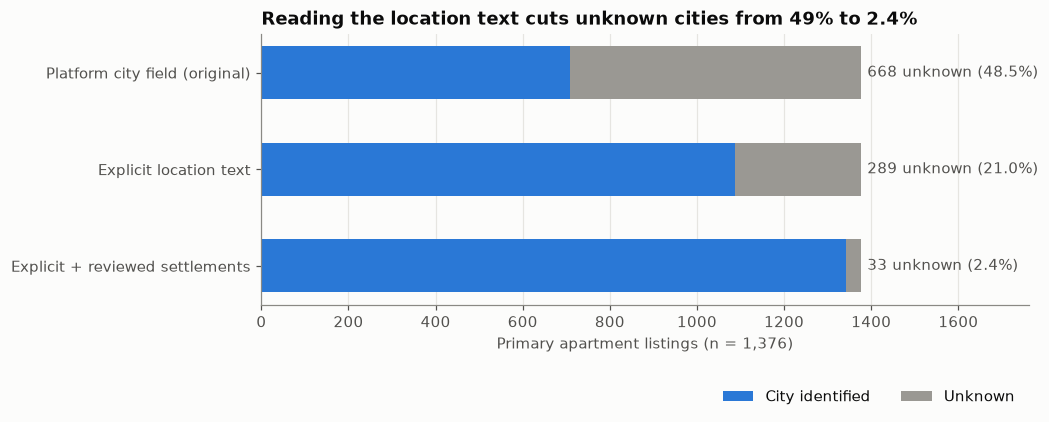

In [20]:
primary = clean[clean['population'] == 'primary']
cov = pd.DataFrame({
    'version': ['Platform city field (original)', 'Explicit location text', 'Explicit + reviewed settlements'],
    'column': ['city_original', 'city_explicit', 'city_clean'],
})
cov['known'] = [int((primary[c] != 'Unknown').sum()) for c in cov['column']]
cov['unknown'] = len(primary) - cov['known']
cov['unknown_%'] = (100 * cov['unknown'] / len(primary)).round(1)
display(cov)
cov.to_csv(RES / 'location_coverage.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 3.2))
y = np.arange(len(cov))[::-1]
ax.barh(y, cov['known'], color=vplot.BLUE, height=0.55, label='City identified')
ax.barh(y, cov['unknown'], left=cov['known'], color=vplot.GRAY, height=0.55, label='Unknown')
for yi, k, u, p in zip(y, cov['known'], cov['unknown'], cov['unknown_%']):
    ax.text(len(primary) + 15, yi, f'{u} unknown ({p}%)', va='center', color=vplot.INK_2)
ax.set_yticks(y, cov['version']); ax.set_xlim(0, len(primary) * 1.28)
ax.set_xlabel('Primary apartment listings (n = 1,376)')
ax.set_title('Reading the location text cuts unknown cities from 49% to 2.4%')
ax.legend(loc='lower right', ncols=2, bbox_to_anchor=(1, -0.42)); ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'eda_05_location_coverage'); plt.show()

**What this code does:** Shows how each city was assigned, by platform, and which location texts remain unknown.

**Why we need it:** This shows where the improvement comes from and that the remaining unknowns are truly ambiguous, not forgotten.

In [21]:
display(pd.crosstab(primary['city_method'], primary['platform'], margins=True))
print('Still unknown:', primary.loc[primary['city_clean'] == 'Unknown', 'neighbourhood'].value_counts().to_dict())
both_known = primary[(primary['city_original'] != 'Unknown') & (primary['city_clean'] != 'Unknown')]
print('Listings where original and cleaned city are both known but different:', int((both_known['city_original'] != both_known['city_clean']).sum()))
mapped_counts = primary.loc[primary['city_method'] == 'Reviewed settlement mapping', 'neighbourhood'].map(vp.norm).value_counts()
mapping_review = mapping.copy()
mapping_review['records_in_primary_population'] = mapping_review['settlement'].map(vp.norm).map(mapped_counts).fillna(0).astype(int)
mapping_review.to_csv(RES / 'settlement_mapping_review.csv', index=False)
print('Primary listings located by the 15 settlement mappings:', int(mapping_review['records_in_primary_population'].sum()))

platform,Estitor,Realitica,Realitica Adriatic,All
city_method,,,,
Ambiguous,0,21,0,21
Conflict,3,0,0,3
Explicit location match,0,382,0,382
Original valid city,398,277,30,705
Reviewed settlement mapping,0,256,0,256
Unknown,0,9,0,9
All,401,945,30,1376


Still unknown: {'Luštica': 7, 'Centar': 7, 'Zelenika': 6, 'Pržno': 6, 'Zeta': 3, 'Gomila': 2, '6': 1, 'Prijevor': 1}
Listings where original and cleaned city are both known but different: 0
Primary listings located by the 15 settlement mappings: 256


**What it means:** the cleaned city **never contradicts** the platform's own city where both exist. The improvement comes only from listings that had no usable city before. 256 primary listings are located by the reviewed settlement mapping, mostly in Herceg Novi (Igalo, Đenovići, Kumbor, …) and the Budva riviera (Bečići, Rafailovići, …).

The remaining 33 unknowns are names that really are ambiguous (*Luštica*, *Centar*, *Zelenika*, *Pržno*), plus Estitor's *Zeta* conflict.

*Pržno* and *Ratiševina* are each unique in the Monstat register, but they were not in the approved list of 15, so they are documented as candidates that were not applied (see `settlement_mapping_review.csv`).

### 7.9 Dates and time trends

**What this code does:** Searches all columns for any date or time information about the listings.

**Why we need it:** The original README mentions ARIMA forecasts. Those need real dates at a regular frequency.

In [22]:
date_like = [c for c in raw.columns if any(k in c.lower() for k in ['date', 'datum', 'time', 'year', 'godin'])]
print('Date-like columns:', date_like)
print('valuation_year filled for real listings:', int(raw.loc[raw['data_origin'].eq('REAL'), 'valuation_year'].notna().sum()))

Date-like columns: ['simulated_year_built', 'valuation_year', 'Year_Built']
valuation_year filled for real listings: 0


**What it means:** the only year-like columns are **simulated** construction years and `valuation_year` of the appraisals. Real listings have **no date at all**. No time series can therefore be built: artificial dates are not created, and the row order is not used as time. Market trend forecasting (ARIMA) stays **future work** and needs dated listings collected regularly.

## 8. Univariate exploration

All charts from here on use the **1,376 primary apartment listings** unless stated otherwise.

**What this code does:** Draws the asking price distribution on a normal scale and on a log scale, with the median marked.

**Why we need it:** Price is the quantity to be predicted. Its shape decides which error measure makes sense, and whether a log transformation could help some models.

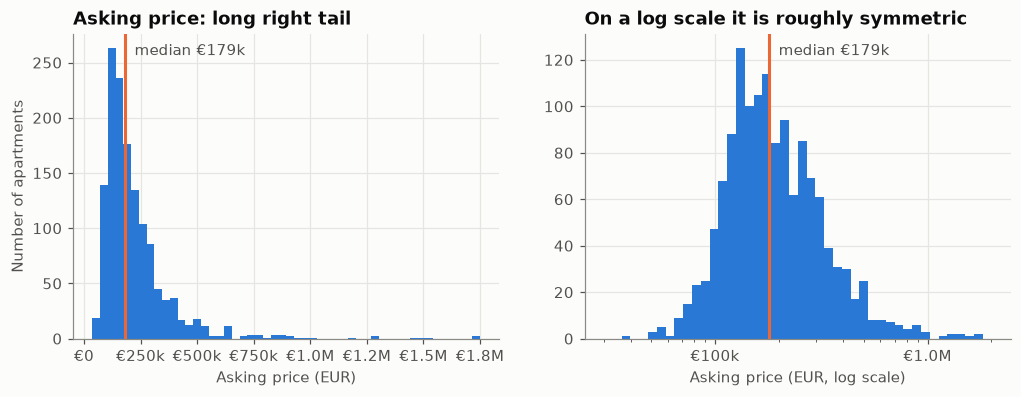

,price_eur
count,1376.0
mean,222724.0
std,162404.0
min,37000.0
10%,105000.0
25%,130000.0
50%,178750.0
75%,263000.0
90%,379500.0
99%,890000.0


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(primary['price_eur'], bins=50, color=vplot.BLUE)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
axes[0].set_xlabel('Asking price (EUR)'); axes[0].set_ylabel('Number of apartments')
axes[0].set_title('Asking price: long right tail')
axes[1].hist(primary['price_eur'], bins=np.logspace(np.log10(3e4), np.log10(2e6), 45), color=vplot.BLUE)
axes[1].set_xscale('log'); axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
axes[1].set_xlabel('Asking price (EUR, log scale)'); axes[1].set_title('On a log scale it is roughly symmetric')
med = primary['price_eur'].median()
for ax in axes:
    ax.axvline(med, color=vplot.ORANGE, lw=2); ax.text(med, ax.get_ylim()[1] * 0.93, f'  median {vplot.euro(med)}', color=vplot.INK_2)
vplot.save(fig, FIG, 'eda_06_price_distribution'); plt.show()
display(primary['price_eur'].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_frame('price_eur'))

**What it means:** most apartments are advertised between about €130,000 and €265,000 (the middle 50%), with a median of about €179,000. A few cost over €1M. Because of this long tail:
- the **mean is higher than the median** (a few expensive flats pull it up);
- a single **large error on a luxury flat** affects RMSE far more than MAE;
- a **log-target** model is worth testing in the modelling notebook.

**What this code does:** Draws the apartment size distribution.

**Why we need it:** Size is expected to be the strongest single driver of total price.

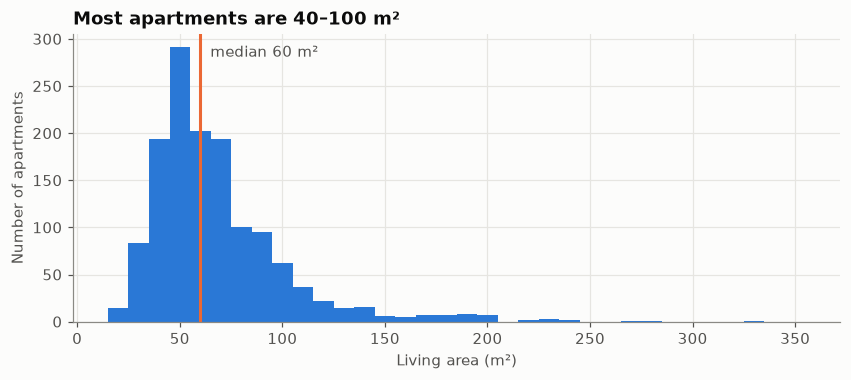

{'count': 1376.0, 'mean': 67.9, 'std': 34.2, 'min': 21.0, '25%': 46.0, '50%': 60.0, '75%': 79.0, 'max': 334.0}


In [24]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(primary['area_m2'], bins=np.arange(15, 360, 10), color=vplot.BLUE)
ax.axvline(primary['area_m2'].median(), color=vplot.ORANGE, lw=2)
ax.text(primary['area_m2'].median(), ax.get_ylim()[1] * 0.92, f"  median {primary['area_m2'].median():.0f} m²", color=vplot.INK_2)
ax.set_xlabel('Living area (m²)'); ax.set_ylabel('Number of apartments')
ax.set_title('Most apartments are 40–100 m²')
vplot.save(fig, FIG, 'eda_07_area_distribution'); plt.show()
print(primary['area_m2'].describe().round(1).to_dict())

**What this code does:** Draws the distribution of the price per m² (price ÷ area).

**Why we need it:** Valuers think in price per m². It allows locations to be compared independently of size. It is computed **from the target**, so it is used only here, never as a model input.

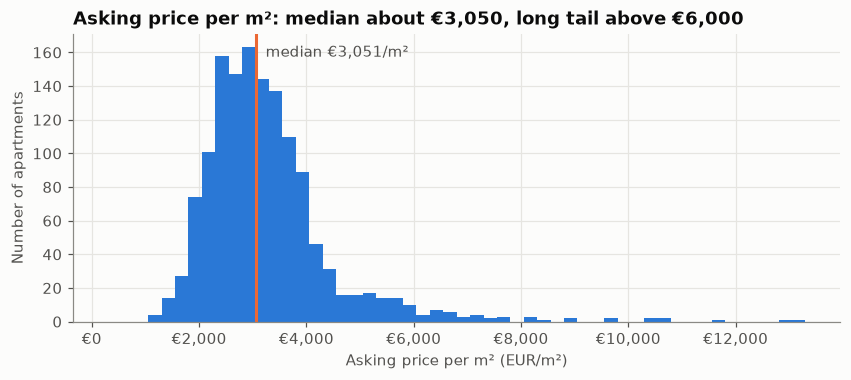

{'count': 1376.0, 'mean': 3265.0, 'std': 1251.0, 'min': 1056.0, '5%': 1878.0, '50%': 3051.0, '95%': 5523.0, 'max': 13131.0}


In [25]:
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(primary['price_per_m2'], bins=np.arange(300, 13500, 250), color=vplot.BLUE)
ax.axvline(primary['price_per_m2'].median(), color=vplot.ORANGE, lw=2)
ax.text(primary['price_per_m2'].median(), ax.get_ylim()[1] * 0.92, f"  median €{primary['price_per_m2'].median():,.0f}/m²", color=vplot.INK_2)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'€{x:,.0f}'))
ax.set_xlabel('Asking price per m² (EUR/m²)'); ax.set_ylabel('Number of apartments')
ax.set_title('Asking price per m²: median about €3,050, long tail above €6,000')
vplot.save(fig, FIG, 'eda_08_price_per_m2_distribution'); plt.show()
print(primary['price_per_m2'].describe(percentiles=[.05, .5, .95]).round(0).to_dict())

**What this code does:** Counts apartments by number of rooms, showing studios and missing values separately.

**Why we need it:** To see whether rooms has enough information to be a model input, and how many values must be filled in.

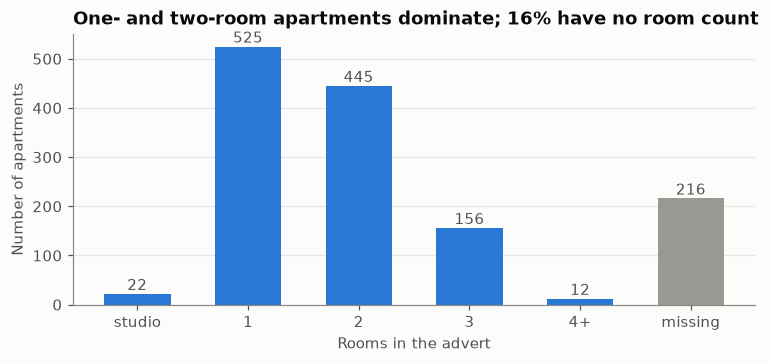

In [26]:
rc = primary['rooms'].map(lambda r: 'missing' if pd.isna(r) else ('studio' if r == 0 else (f'{int(r)}' if r < 4 else '4+')))
rc = rc.value_counts().reindex(['studio', '1', '2', '3', '4+', 'missing'])
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(rc.index, rc.values, color=[vplot.GRAY if i == 'missing' else vplot.BLUE for i in rc.index], width=0.6)
for x, v in enumerate(rc.values):
    ax.text(x, v + 8, f'{v}', ha='center', color=vplot.INK_2)
ax.set_xlabel('Rooms in the advert'); ax.set_ylabel('Number of apartments')
ax.set_title('One- and two-room apartments dominate; 16% have no room count')
ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'eda_09_rooms'); plt.show()

**What this code does:** Counts apartments per (cleaned) city, with Unknown shown separately in grey.

**Why we need it:** City comparisons are only fair where there are enough listings. This also shows how strongly the sample leans towards Podgorica and the coast.

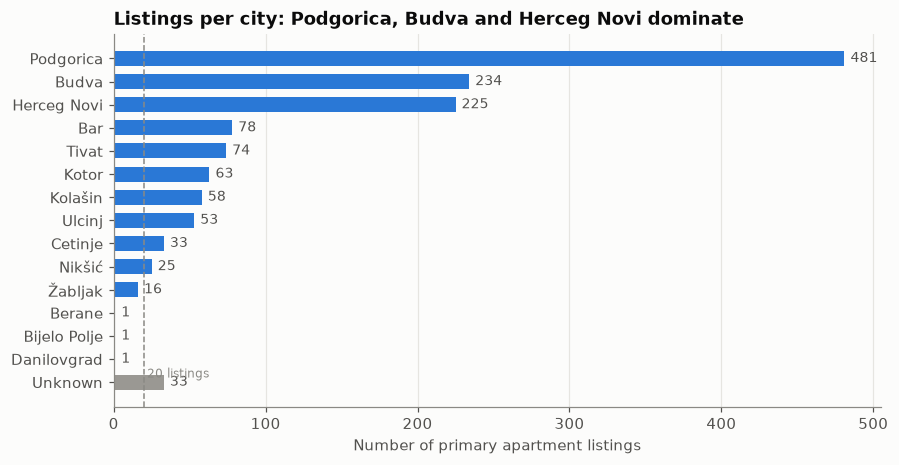

In [27]:
cc = primary['city_clean'].value_counts()
order = [c for c in cc.index if c != 'Unknown'] + ['Unknown']
cc = cc.reindex(order)
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(cc.index[::-1], cc.values[::-1], color=[vplot.GRAY if c == 'Unknown' else vplot.BLUE for c in cc.index[::-1]], height=0.65)
for y, v in enumerate(cc.values[::-1]):
    ax.text(v + 4, y, str(v), va='center', color=vplot.INK_2, fontsize=9)
ax.axvline(20, color=vplot.INK_3, ls='--', lw=1); ax.text(22, 0.2, '20 listings', color=vplot.INK_3, fontsize=8)
ax.set_xlabel('Number of primary apartment listings'); ax.set_title('Listings per city: Podgorica, Budva and Herceg Novi dominate')
ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'eda_10_listings_by_city'); plt.show()

**What it means:** three municipalities hold 68% of the listings. Berane, Bijelo Polje and Danilovgrad have one listing each, so nothing can be said about their prices. City comparisons require **at least 20 listings**: with fewer, a single unusual advert can move the median a lot.

## 9. Bivariate exploration

**What this code does:** Plots area against price (both on log scales), coloured by platform.

**Why we need it:** The core relationship the model must learn. The log scale spreads out the many small flats, and the colours show whether the platforms behave differently.

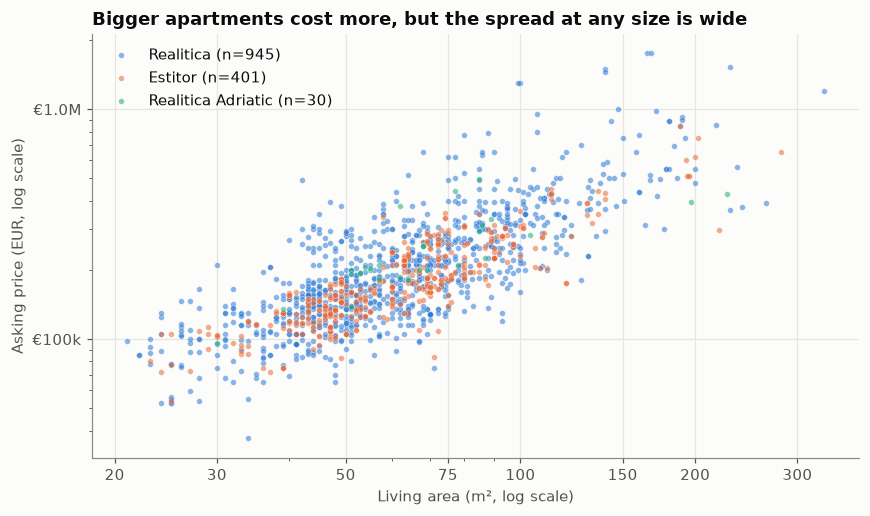

Correlation of log(area) and log(price): 0.787
Spearman (rank) correlation area vs price: 0.774


In [28]:
fig, ax = plt.subplots(figsize=(9, 5))
for p, col in vplot.PLATFORM_COLORS.items():
    d = primary[primary['platform'] == p]
    ax.scatter(d['area_m2'], d['price_eur'], s=14, alpha=0.55, color=col, edgecolors='white', linewidths=0.3, label=f'{p} (n={len(d)})')
ax.set_xscale('log'); ax.set_yscale('log')
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xticks([20, 30, 50, 75, 100, 150, 200, 300], ['20', '30', '50', '75', '100', '150', '200', '300'])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_xlabel('Living area (m², log scale)'); ax.set_ylabel('Asking price (EUR, log scale)')
ax.set_title('Bigger apartments cost more, but the spread at any size is wide')
ax.legend(loc='upper left')
vplot.save(fig, FIG, 'eda_11_area_vs_price'); plt.show()
print('Correlation of log(area) and log(price):', round(np.corrcoef(np.log(primary['area_m2']), np.log(primary['price_eur']))[0, 1], 3))
print('Spearman (rank) correlation area vs price:', round(primary[['area_m2', 'price_eur']].corr(method='spearman').iloc[0, 1], 3))

**What it means:** size and price are strongly related. But at, for example, 60 m² the asking price ranges from under €100,000 to over €400,000. Size alone cannot explain that spread. Location, condition, view and quality matter, and most of these are **not in the data**.

**What this code does:** Computes the median price per m² for every city with at least 20 listings, with a 95% bootstrap interval for the median, and draws it.

**Why we need it:** This answers how asking prices differ between cities. The interval shows how uncertain each median is, given the number of listings.

,city,n,median_eur_m2,ci_low,ci_high
2,Cetinje,33,1829.0,1703.0,1957.0
6,Nikšić,25,1842.0,1725.0,2154.0
9,Ulcinj,53,2283.0,2100.0,2353.0
4,Kolašin,58,2500.0,2456.0,2947.0
7,Podgorica,481,2833.0,2761.0,2923.0
0,Bar,78,2957.0,2854.0,3050.0
3,Herceg Novi,225,3298.0,3163.0,3462.0
1,Budva,234,3566.0,3392.0,3663.0
5,Kotor,63,3784.0,3365.0,3939.0
8,Tivat,74,4000.0,3853.0,4291.0


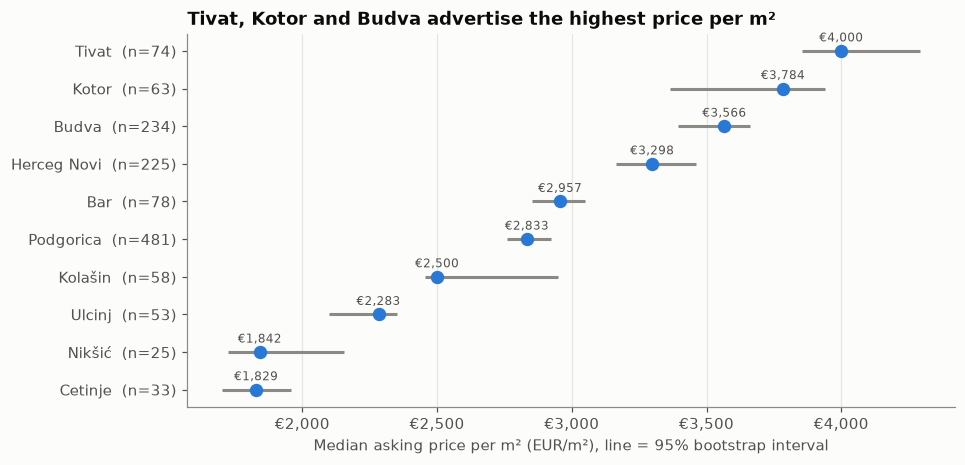

In [29]:
rng = np.random.default_rng(42)
rows = []
for city, d in primary[primary['city_clean'] != 'Unknown'].groupby('city_clean'):
    if len(d) < 20:
        continue
    v = d['price_per_m2'].to_numpy()
    boots = np.median(rng.choice(v, size=(2000, len(v)), replace=True), axis=1)
    rows.append({'city': city, 'n': len(v), 'median_eur_m2': np.median(v),
                 'ci_low': np.percentile(boots, 2.5), 'ci_high': np.percentile(boots, 97.5)})
city_ppm = pd.DataFrame(rows).sort_values('median_eur_m2')
display(city_ppm.round(0))
city_ppm.to_csv(RES / 'city_median_price_per_m2.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(city_ppm))
ax.hlines(y, city_ppm['ci_low'], city_ppm['ci_high'], color=vplot.INK_3, lw=2)
ax.scatter(city_ppm['median_eur_m2'], y, s=60, color=vplot.BLUE, zorder=3)
ax.set_yticks(y, [f"{c}  (n={n})" for c, n in zip(city_ppm['city'], city_ppm['n'])])
for yi, m in zip(y, city_ppm['median_eur_m2']):
    ax.text(m, yi + 0.25, f'€{m:,.0f}', ha='center', color=vplot.INK_2, fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'€{x:,.0f}'))
ax.set_xlabel('Median asking price per m² (EUR/m²), line = 95% bootstrap interval')
ax.set_title('Tivat, Kotor and Budva advertise the highest price per m²')
ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'eda_12_median_price_per_m2_by_city'); plt.show()

**What it means:** Tivat, Kotor and Budva have the highest median asking prices per m². Podgorica, Kolašin, Ulcinj and Bar are in the middle, and Nikšić and Cetinje are lowest. The intervals are wide for the smaller cities (25–35 listings), so neighbouring cities with overlapping intervals should not be ranked against each other with confidence.

These are **asking** prices from the collected adverts. They are not official market statistics for the cities.

**What this code does:** Compares asking price across room counts with box plots.

**Why we need it:** Rooms and area overlap (bigger flats have more rooms). The question is whether rooms add anything beyond size.

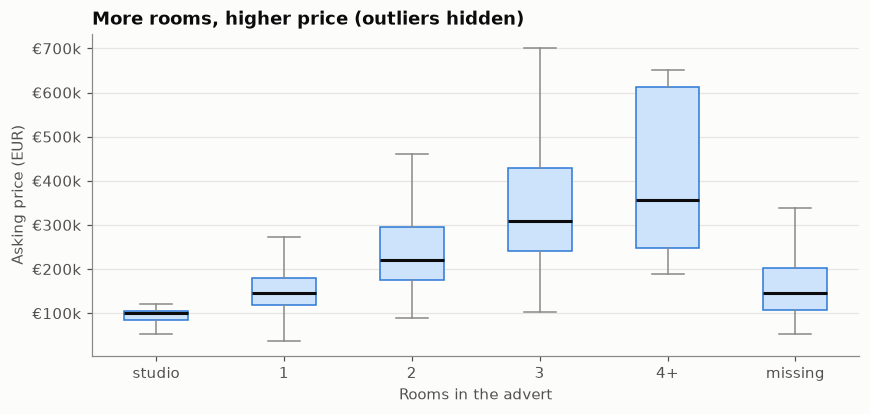

           price_eur  area_m2  rooms
price_eur       1.00     0.77   0.60
area_m2         0.77     1.00   0.81
rooms           0.60     0.81   1.00


In [30]:
rk = primary.assign(rooms_label=primary['rooms'].map(lambda r: 'missing' if pd.isna(r) else ('studio' if r == 0 else (f'{int(r)}' if r < 4 else '4+'))))
order = ['studio', '1', '2', '3', '4+', 'missing']
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.boxplot([rk.loc[rk['rooms_label'] == o, 'price_eur'] for o in order], tick_labels=order, showfliers=False,
           patch_artist=True, boxprops=dict(facecolor='#cde2fb', color=vplot.BLUE), medianprops=dict(color=vplot.INK, lw=2),
           whiskerprops=dict(color=vplot.INK_3), capprops=dict(color=vplot.INK_3))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
ax.set_xlabel('Rooms in the advert'); ax.set_ylabel('Asking price (EUR)')
ax.set_title('More rooms, higher price (outliers hidden)'); ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'eda_13_price_by_rooms'); plt.show()
print(primary[['price_eur', 'area_m2', 'rooms']].corr(method='spearman').round(2))

**What it means:** prices rise with the number of rooms, but rooms and area are strongly related (Spearman ≈ 0.8). The model has to learn how much rooms adds **on top of** size.

### 9.1 Platform differences and sampling limits

**What this code does:** Compares the three platforms: which cities they cover, and their prices and sizes. It then compares Estitor and Realitica **within Podgorica only**.

**Why we need it:** If one platform covers only one city, or has different kinds of flats, the model may partly learn the platform. A within-Podgorica comparison is fairer, because it removes the city effect.

In [31]:
plat = primary.groupby('platform').agg(listings=('record_id', 'size'), cities=('city_clean', 'nunique'),
                                      median_price=('price_eur', 'median'), median_area=('area_m2', 'median'),
                                      median_eur_m2=('price_per_m2', 'median'))
display(plat.round(0))
plat.to_csv(RES / 'platform_summary.csv')
display(pd.crosstab(primary['city_clean'], primary['platform']).loc[lambda t: t.sum(axis=1) >= 20])
pg = primary[primary['city_clean'] == 'Podgorica']
display(pg.groupby('platform')[['price_eur', 'area_m2', 'price_per_m2']].median().round(0).assign(n=pg['platform'].value_counts()))
est_nb = primary[primary['platform'] == 'Estitor']['neighbourhood'].value_counts()
print(f'Estitor: {len(est_nb)} Podgorica neighbourhoods, listings per neighbourhood: min {est_nb.min()}, max {est_nb.max()}')

,listings,cities,median_price,median_area,median_eur_m2
platform,,,,,
Estitor,401,2,169000.0,63.0,2872.0
Realitica,945,15,180000.0,60.0,3125.0
Realitica Adriatic,30,5,208300.0,66.0,3649.0


platform,Estitor,Realitica,Realitica Adriatic
city_clean,,,
Bar,0,74,4
Budva,0,216,18
Cetinje,0,33,0
Herceg Novi,0,224,1
Kolašin,0,58,0
Kotor,0,63,0
Nikšić,0,25,0
Podgorica,398,83,0
Tivat,0,71,3


,price_eur,area_m2,price_per_m2,n
platform,,,,
Estitor,169000.0,63.0,2880.0,398
Realitica,150000.0,60.0,2618.0,83


Estitor: 26 Podgorica neighbourhoods, listings per neighbourhood: min 1, max 20


**What this code does:** Draws price and area by platform side by side (box plots), for Podgorica only, so the comparison is not mixed with city differences.

**Why we need it:** To show visually that the two platforms sample somewhat different flats even in the same city.

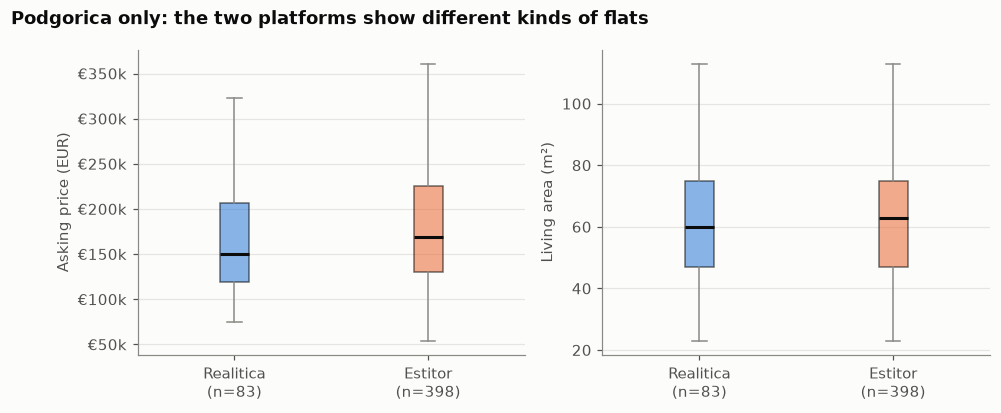

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
plats = ['Realitica', 'Estitor']
for ax, col, lab in [(axes[0], 'price_eur', 'Asking price (EUR)'), (axes[1], 'area_m2', 'Living area (m²)')]:
    bp = ax.boxplot([pg.loc[pg['platform'] == p, col] for p in plats], tick_labels=[f'{p}\n(n={(pg.platform == p).sum()})' for p in plats],
                    showfliers=False, patch_artist=True, medianprops=dict(color=vplot.INK, lw=2),
                    whiskerprops=dict(color=vplot.INK_3), capprops=dict(color=vplot.INK_3))
    for patch, p in zip(bp['boxes'], plats):
        patch.set_facecolor(vplot.PLATFORM_COLORS[p]); patch.set_alpha(0.55)
    ax.set_ylabel(lab); ax.grid(axis='x', visible=False)
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro))
fig.suptitle('Podgorica only: the two platforms show different kinds of flats', x=0.01, ha='left', fontweight='bold')
vplot.save(fig, FIG, 'eda_14_platform_podgorica'); plt.show()

**What it means:**
- **Estitor covers only Podgorica**, with at most 20 adverts per neighbourhood (26 neighbourhoods; most have 18–20). That is how the data were scraped, not how the market looks.
- **Realitica Adriatic** has only 30 coastal listings.
- Even within Podgorica, the platforms differ somewhat: the median Estitor flat is advertised at €169,000 (63 m²) and the median Realitica flat at €150,000 (60 m²).

So the data are a **convenience sample** of online adverts. The city medians above describe *this sample*, not the whole Montenegrin market. `platform` is kept for auditing and error analysis only, not as a model feature, because it describes how the data were collected, not the flat.

## 10. Key findings

1. **Most of the raw file is not market data.** Only 1,986 of 6,913 rows are real adverts. 2,000 simulated rows are **mislabelled** as online listings in two columns, and a multi-column provenance check was needed to exclude them.
2. **The final population is 1,376 real apartment listings** (plus 4 valid luxury listings for sensitivity). Every exclusion has a recorded reason. The biggest real-data problems were **36 rentals** mixed into sale prices and **47 exact re-posts**.
3. **Location coverage improved from 51% to 97.6%** of listings (unknown cities: 668 → 33). This came from reading the structured location text and 15 settlement names verified against the Monstat register, without contradicting any existing city.
4. **Asking prices are right-skewed** (median ≈ €179k, a few above €1M). The median asking price per m² is about €3,050 (90% of listings between ≈ €1,900 and €5,500).
5. **Size is the strongest single signal**, but prices for flats of the same size vary widely.
6. **Location matters:** the coastal municipalities (Tivat, Kotor, Budva) have the highest median asking price per m². Small cities have too few listings for reliable comparison.
7. **The sample is not representative:** the platforms cover different areas (Estitor = Podgorica only, about 20 per neighbourhood), and there are **no dates**, so no time trends can be studied.
8. **172 listings form 74 groups of probable repeats** (17 across platforms). These groups must stay together when the data are split for testing.

## 11. Decisions carried forward

| Decision | Reason |
|---|---|
| Target = `price_eur` (asking price, EUR) | It is what the data contain; it is not a sale price or an appraisal |
| Primary population = 1,376 listings (`population == 'primary'`) | Real apartment sale adverts that passed all validity rules and the earlier research ranges |
| Sensitivity population = 1,380 (adds the 4 valid luxury listings) | To show the effect of the ranges honestly |
| Inputs: `area_m2`, `rooms` (+ `is_studio`), city | Available, not derived from the price, and real (not simulated) |
| Three city versions: `city_original`, `city_explicit`, `city_clean` | To **measure** what the location cleaning is worth, on the same rows and splits |
| Not used as inputs: `price_per_m2` and all other price-derived columns, bathrooms, `simulated_*` columns, text, URLs, `platform` | Target leakage, mostly missing, artificial, private, or a property of the data collection |
| Missing rooms are filled **inside** the model pipeline (median of the training data + a "was missing" indicator) | So that no information from the test data is used |
| `repeat_group` defines groups for group-aware train/test splitting and cross-validation | So that the same flat is never in both training and test data |
| No time-series model | There are no listing dates |

## 12. Export

**What this code does:** Saves the processed dataset and the audit tables to `data/processed/` and `docs/results/`, prints their checksums, and saves a **private** link table (record ID ↔ platform ID and URL) to `data/private/`, which is excluded from Git.

**Why we need it:** `02_modelling.ipynb` must load this file instead of relying on variables in this notebook's memory. The public file contains no URLs, platform IDs or free text, but any record can still be traced back to its source locally if needed.

In [33]:
out_path = PROCESSED / 'valora_apartments_clean.csv'
clean.to_csv(out_path, index=False, lineterminator='\n')
real[['record_id', 'platform', 'listing_id', 'url']].to_csv(ROOT / 'data' / 'private' / 'record_id_map_PRIVATE.csv', index=False)
print('Saved:', out_path.relative_to(ROOT), '|', clean.shape, '| sha256', vp.file_sha256(out_path)[:16])
for f in ['cleaning_flow.csv', 'exclusion_summary.csv', 'exclusion_log.csv']:
    print('Saved:', (PROCESSED / f).relative_to(ROOT))

Saved: data\processed\valora_apartments_clean.csv | (1380, 19) | sha256 64d0339e54dd5185
Saved: data\processed\cleaning_flow.csv
Saved: data\processed\exclusion_summary.csv
Saved: data\processed\exclusion_log.csv


**What this code does:** Reloads the exported file and checks that it has the same content as the table in memory, and that it holds only allowed rows and columns.

**Why we need it:** A last guard: what the modelling notebook reads must be exactly what this notebook produced, with no URLs or text.

In [34]:
check = pd.read_csv(out_path)
pd.testing.assert_frame_equal(check, clean.reset_index(drop=True), check_dtype=False)
assert set(check['population']) == {'primary', 'extended only'}
assert not {'url', 'listing_id', 'naslov', 'opis'} & set(check.columns)
assert check['price_eur'].gt(0).all() and np.isfinite(check['area_m2']).all()
print('Export verified:', check['population'].value_counts().to_dict())

Export verified: {'primary': 1376, 'extended only': 4}


## 13. Appendix

### 13.1 Comparison with the earlier cleaning

**What this code does:** Loads the earlier partly cleaned file (`valora_cleaned_step2.csv`) **only to compare**: how many apartments and unknown cities the earlier procedure had.

**Why we need it:** To document why the new numbers differ from the earlier notebooks (1,432 in the old EDA, 1,473 in the old modelling).

In [35]:
step2 = pd.read_csv(ROOT / 'data' / 'raw' / vp.STEP2_FILE, low_memory=False, dtype={'listing_id': str})
old = step2[step2['data_origin'].eq('REAL') & step2['property_type_clean'].eq('Apartment')]
comparison = pd.DataFrame({
    'procedure': ['Earlier modelling (step2 file)', 'This notebook (primary)'],
    'apartments': [len(old), int((clean['population'] == 'primary').sum())],
    'unknown_city': [int(old['city_clean'].isna().sum()), int((primary['city_clean'] == 'Unknown').sum())],
    'rentals_included': [int((old['price_eur'] < 10000).sum()), 0],
})
display(comparison)

,procedure,apartments,unknown_city,rentals_included
0,Earlier modelling (step2 file),1473,703,36
1,This notebook (primary),1376,33,0


The earlier modelling used 1,473 apartments, including 36 rentals, 47 re-posts, 7 houses and 3 invalid values, and had 703 unknown cities. The earlier EDA (1,432 rows) was run on a different upload that is not in the repository, so its exact numbers cannot be reproduced. Its price range filters removed most rentals but kept the re-posts, and it matched city names as substrings.

The original notebooks are kept unchanged in `archive/original_notebooks/`. The full history is in `docs/research_history.md`.